# Divinity demo

Divinity forecasts a single timeseries automatically. It decides for itself whether there is a trend, which seasonal cycles are real, and how much autocorrelation is left over. It then gives a forecast with a prediction interval that widens as honestly as the data allow.

This notebook walks through

1. the three line quick start
2. dated data, where seasonal periods come from the frequency
3. the tricky cases that trip up naive forecasters
4. the options you might want to change
5. a coverage check that the intervals mean what they say

Every series here comes from `divinity.synthetic`, so the true future is known and you can judge the forecasts yourself.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import divinity as dv
from divinity import synthetic

warnings.filterwarnings("ignore")
%matplotlib inline

## 1. Quick start

A linear trend, a 20 step cycle and noise. The model is not told about either component.

In [2]:
case = synthetic.make("trend_seasonal")
y, truth = case.history, case.future

model = dv.Forecaster().fit(y)
result = model.predict(steps=40)
print(model.summary())
result.head()

Divinity forecaster
  observations   200
  log scale      no
  trend          linear
  seasonality    20 (1 harmonic, detected)
  residuals      ARIMA(0, 0, 0)


,forecast,lower,upper
200,9.977226,9.017514,10.936938
201,10.649815,9.688883,11.610746
202,11.259711,10.297663,12.221759
203,11.752061,10.789233,12.714889
204,12.083518,11.120366,13.046670


`predict` returns a DataFrame with the forecast and the bounds of a 95% prediction interval. `plot` draws it, and `actual` overlays the true future for comparison.

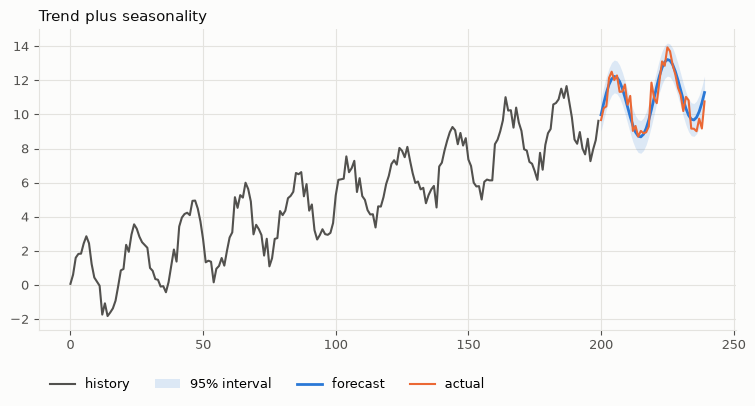

In [3]:
model.plot(result, actual=truth, title="Trend plus seasonality");

If you only want the numbers, there is a one liner.

In [4]:
dv.forecast(y, steps=5)

,forecast,lower,upper
200,9.977226,9.017514,10.936938
201,10.649815,9.688883,11.610746
202,11.259711,10.297663,12.221759
203,11.752061,10.789233,12.714889
204,12.083518,11.120366,13.046670


## 2. Dated data

Give it a pandas Series with a `DatetimeIndex` and the forecast comes back with future dates. The frequency also supplies sensible candidate periods (7 and 365.25 for daily data, 12 for monthly, 24 and 168 for hourly). Weekly seasonality with a sharp weekend dip needs several Fourier harmonics, and the model adds them only as needed.

Divinity forecaster
  observations   1095
  frequency      D
  log scale      no
  trend          linear
  seasonality    365.25 (1 harmonic), 7 (3 harmonics)
  residuals      ARIMA(0, 0, 0)


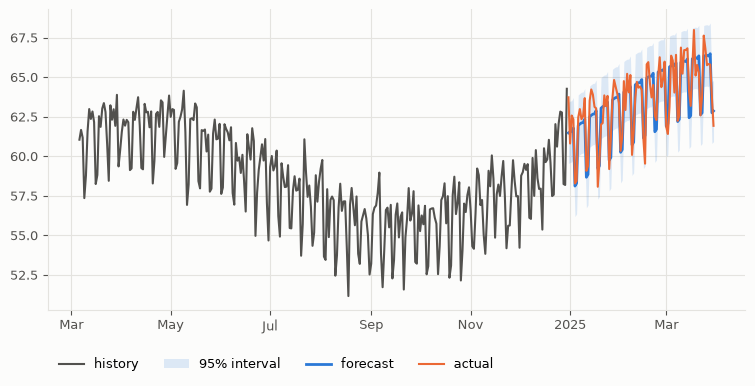

In [5]:
case = synthetic.make("daily_multi_seasonal")
model = dv.Forecaster().fit(case.history)
result = model.predict(case.steps)
print(model.summary())
model.plot(result, actual=case.future, history=300);

If some dates are missing entirely the frequency cannot be inferred. Pass it explicitly and the gaps are treated as missing values.

```python
model = dv.Forecaster().fit(y, freq="D")
```

## 3. Cases designed to fool a forecaster

Each panel below is a different trap. The subtitle shows what the model decided. In every case the orange line is the true future, which the model never saw.

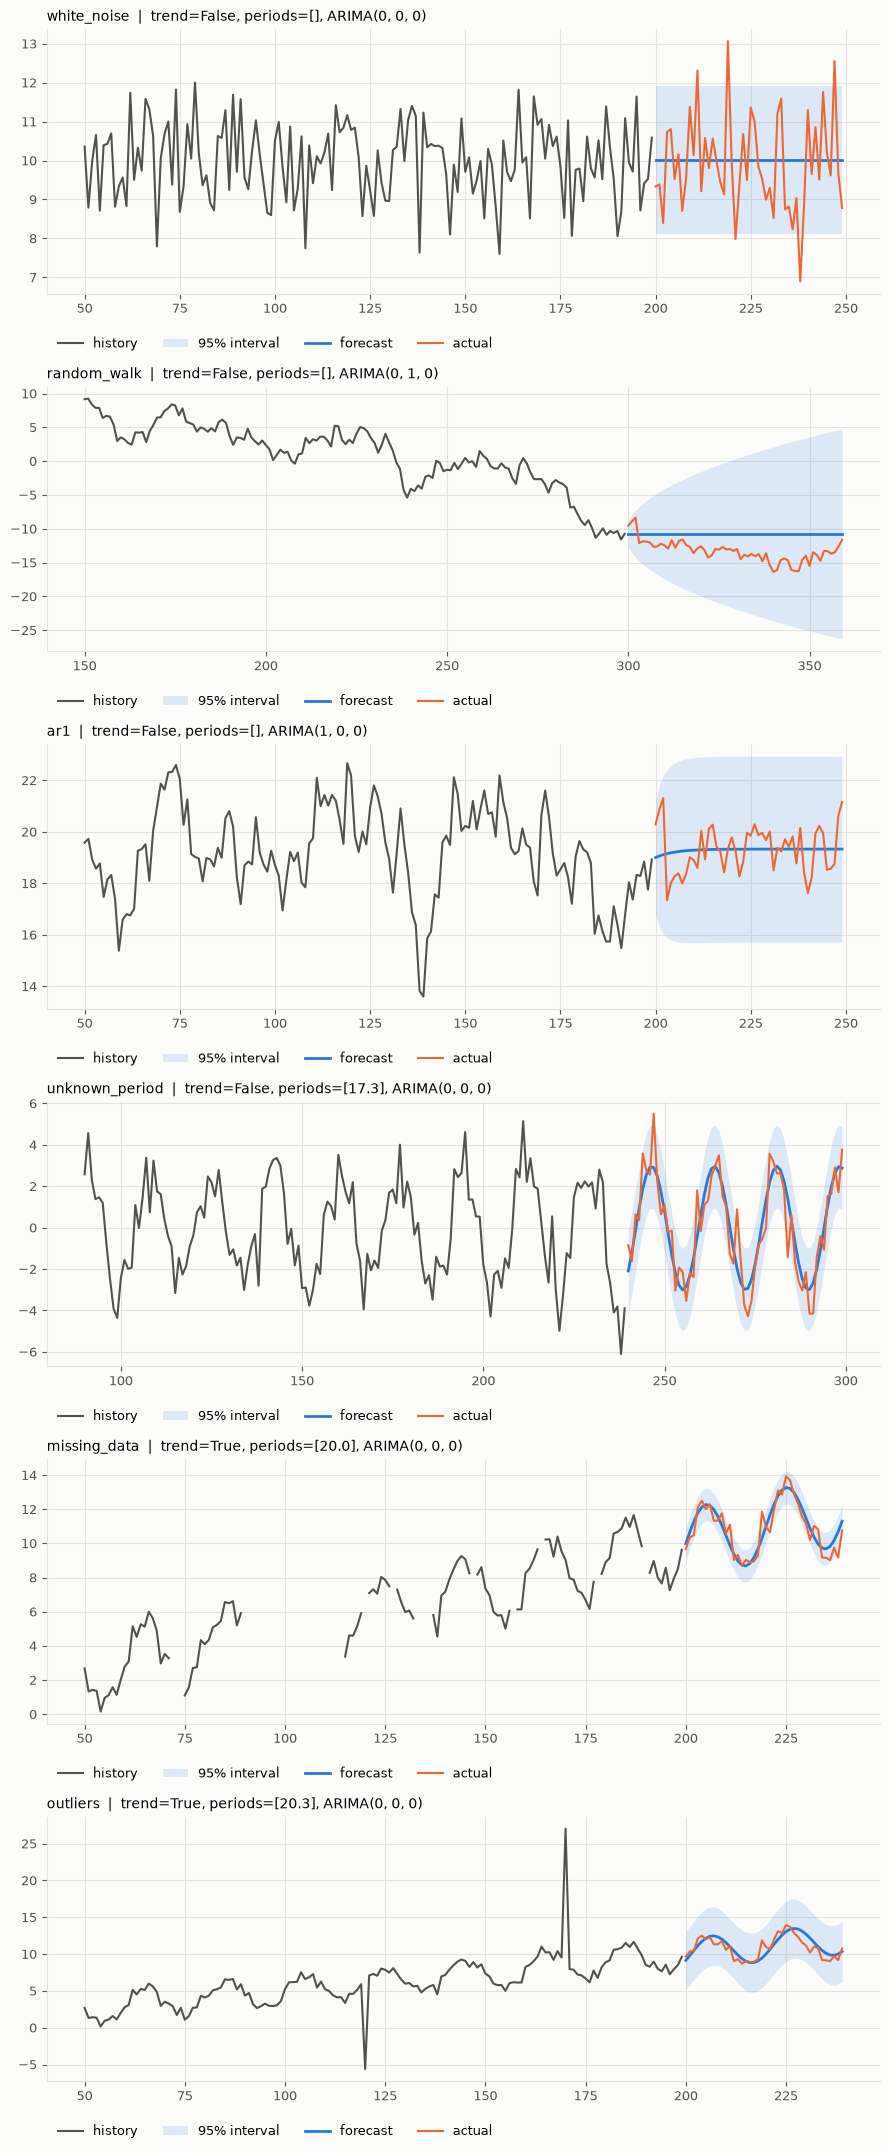

In [6]:
tricky = ["white_noise", "random_walk", "ar1", "unknown_period", "missing_data", "outliers"]
fig, axes = plt.subplots(len(tricky), 1, figsize=(9, 3.6 * len(tricky)))
for ax, name in zip(axes, tricky):
    case = synthetic.make(name)
    model = dv.Forecaster(**case.options).fit(case.history)
    model.plot(model.predict(case.steps), actual=case.future, ax=ax, history=150)
    c = model.components_
    ax.set_title(
        "{}  |  trend={}, periods={}, ARIMA{}".format(
            name, c["trend"], [round(p, 1) for p in c["seasonal_periods"]], c["arima_order"]
        ),
        loc="left", fontsize=10,
    )
fig.tight_layout()

What to notice

- **white_noise.** No trend and no seasonality, just a flat line at the mean. A model that tests dozens of candidate periods will find one by chance unless it pays for the search, and divinity does.
- **random_walk.** Ordinary least squares sees a "significant" trend in almost every random walk. Divinity reselects features allowing for autocorrelated errors, finds nothing deterministic and switches to a differenced model, so the interval fans out.
- **ar1.** Strongly autocorrelated but stationary. The forecast decays back to the mean instead of being treated as a random walk.
- **unknown_period.** A period of 17.3 steps found from the periodogram without being specified.
- **missing_data and outliers.** Gaps are handled natively, and a few large spikes do not derail the fit.

## 4. Options

The defaults are meant to be right most of the time. These are the ones worth knowing.

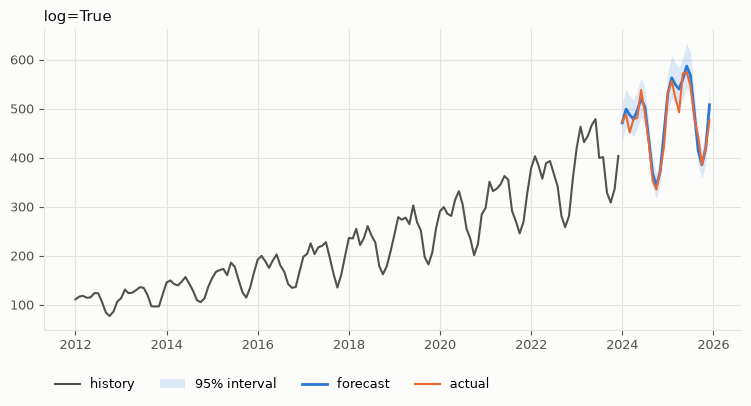

In [7]:
case = synthetic.make("monthly_multiplicative")

# seasonal swings that grow with the level: fit on the log scale
model = dv.Forecaster(log=True).fit(case.history)
model.plot(model.predict(case.steps), actual=case.future, title="log=True");

In [8]:
y = synthetic.make("trend_seasonal").history

dv.Forecaster(
    seasonal_periods=[20],   # periods you know about, in time steps
    detect_periods=False,    # do not search the data for others
    trend="linear",          # "auto", "linear" or None
    arima=(1, 0, 0),         # "auto", a fixed (p, d, q) or None
    interval=0.8,            # default interval coverage
).fit(y).predict(3)

,forecast,lower,upper
200,9.988480,9.362274,10.614686
201,10.650481,10.023034,11.277929
202,11.260005,10.631746,11.888265


Everything the model chose is available as a dict, and the in-sample fit as a Series.

In [9]:
model = dv.Forecaster().fit(y)
model.components_

{'trend': True,
 'seasonal_periods': {20.0: 1},
 'detected_periods': [20.0],
 'evolving_period': None,
 'arima_order': (0, 0, 0),
 'seasonal_order': None}

## 5. Do the intervals mean what they say?

A 95% interval should contain the truth about 95% of the time. Here are 30 fresh random seeds for a few scenarios. The full table over 100 seeds and all scenarios is in the README, produced by `benchmarks/run_benchmark.py`.

In [10]:
rows = []
for name in ["trend_seasonal", "random_walk", "ar1", "white_noise"]:
    for seed in range(30):
        case = synthetic.make(name, seed=seed)
        fc = dv.Forecaster(**case.options).fit(case.history).predict(case.steps)
        inside = (case.future.values >= fc["lower"].values) & (case.future.values <= fc["upper"].values)
        rows.append({"scenario": name, "coverage": inside.mean()})
pd.DataFrame(rows).groupby("scenario")["coverage"].mean().round(3)

scenario
ar1               0.898
random_walk       0.905
trend_seasonal    0.940
white_noise       0.951
Name: coverage, dtype: float64

## Limitations

- Trends are linear. A series that bends or saturates will be extrapolated in a straight line.
- Sudden level shifts and regime changes are not modelled. The model will average across them.
- Outliers are not removed, they widen the interval a little instead.
- Seasonality is assumed to have a fixed shape (or a shape proportional to the level with `log=True`).